## Loading Dataset

In [3]:
import pandas as pd

df = pd.read_excel("Customer_Churn_Dataset.xlsx")

## Exploratory Data Analysis

In [4]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,0,0,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,0,0,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,3,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.shape

(7043, 23)

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
numAdminTickets     0
numTechTickets      0
Churn               0
dtype: int64

In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,numAdminTickets,numTechTickets
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,0.515689,0.419566
std,0.368612,24.559481,30.090047,1.275299,1.250117
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,0.000000,0.000000
50%,0.000000,29.000000,70.350000,0.000000,0.000000
75%,0.000000,55.000000,89.850000,0.000000,0.000000
max,1.000000,72.000000,118.750000,5.000000,9.000000


In [11]:
for col in df.select_dtypes(include="object"):
    print(col, ":", df[col].unique())

customerID : <ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
gender : <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner : <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup : <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtectio

C:\Users\Sushanth CD\AppData\Local\Temp\ipykernel_42248\1325116304.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object"):


In [12]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges         object
numAdminTickets       int64
numTechTickets        int64
Churn                   str
dtype: object

In [13]:
df["TotalCharges"].dtype

dtype('O')

In [14]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [15]:
df["TotalCharges"].apply(lambda x: type(x)).value_counts()

TotalCharges
<class 'float'>    6708
<class 'int'>       324
<class 'str'>        11
Name: count, dtype: int64

In [16]:
df[df["TotalCharges"].apply(lambda x: pd.to_numeric(x, errors="coerce")).isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,0,0,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.25,,5,0,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,Yes,Two year,No,Mailed check,80.85,,0,0,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.75,,1,0,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,No,Credit card (automatic),56.05,,0,0,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,19.85,,0,0,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.35,,0,0,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.00,,5,0,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,19.70,,0,0,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,No,Two year,No,Mailed check,73.35,,0,0,No


In [17]:
df[df["TotalCharges"].apply(lambda x: isinstance(x, str))]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,0,0,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.25,,5,0,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,Yes,Two year,No,Mailed check,80.85,,0,0,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.75,,1,0,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,No,Credit card (automatic),56.05,,0,0,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,19.85,,0,0,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.35,,0,0,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.00,,5,0,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,19.70,,0,0,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,No,Two year,No,Mailed check,73.35,,0,0,No


In [18]:
df[df["TotalCharges"].apply(lambda x: isinstance(x, str))]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,0,0,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.25,,5,0,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,Yes,Two year,No,Mailed check,80.85,,0,0,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.75,,1,0,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,No,Credit card (automatic),56.05,,0,0,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,19.85,,0,0,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.35,,0,0,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.00,,5,0,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,19.70,,0,0,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,No,Two year,No,Mailed check,73.35,,0,0,No


In [19]:
df.loc[
    df["TotalCharges"].apply(lambda x: isinstance(x, str)),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [20]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

In [95]:
df["TotalCharges"].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

In [21]:
df["TotalCharges"].dtype

dtype('float64')

In [22]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [23]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [24]:
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [25]:
df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

In [26]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [27]:
df.groupby("Churn")["MonthlyCharges"].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

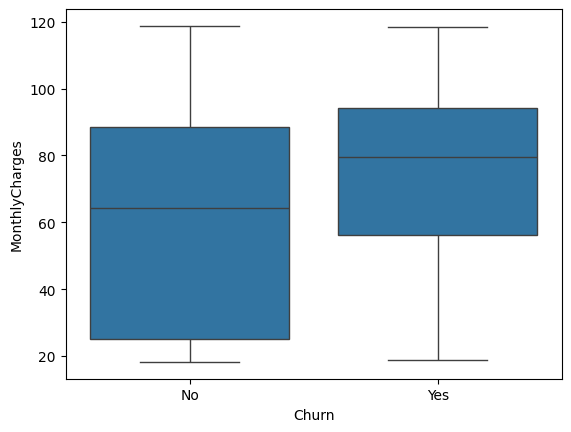

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["Churn"], y=df["MonthlyCharges"])
plt.show()

In [29]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [30]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100 

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [31]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


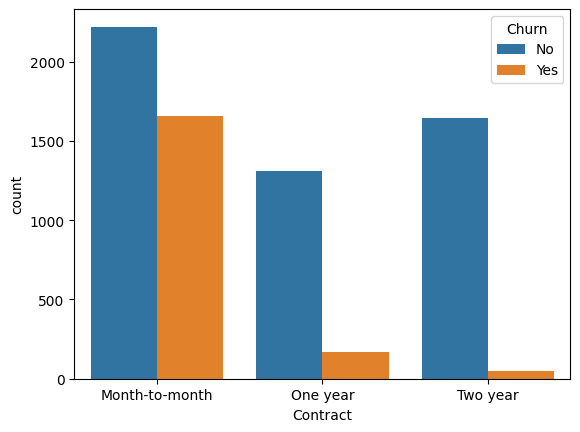

In [32]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()

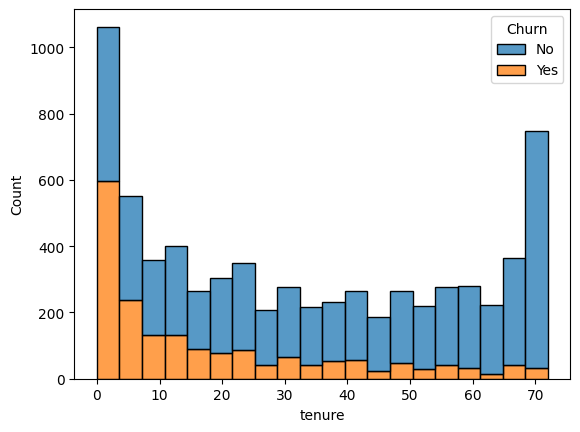

In [33]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=20, multiple="stack")
plt.show()

In [34]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
)

In [35]:
pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
tenure_group,,
0-12,52.321839,47.678161
13-24,71.289062,28.710938
25-36,78.365385,21.634615
37-48,80.971129,19.028871
49-60,85.576923,14.423077
61-72,93.390192,6.609808


In [36]:
df["tenure_group"].isna().sum()

np.int64(11)

In [37]:
df[df["tenure_group"].isna()][["tenure", "TotalCharges", "Churn"]]

,tenure,TotalCharges,Churn
488,0,0.0,No
753,0,0.0,No
936,0,0.0,No
1082,0,0.0,No
1340,0,0.0,No
3331,0,0.0,No
3826,0,0.0,No
4380,0,0.0,No
5218,0,0.0,No
6670,0,0.0,No


In [38]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


In [39]:
pd.crosstab(
    [df["Contract"], df["TechSupport"]],
    df["Churn"],
    normalize="index"
) * 100

Churn                                      No        Yes
Contract       TechSupport                              
Month-to-month No                   49.626866  50.373134
               No internet service  81.106870  18.893130
               Yes                  69.299553  30.700447
One year       No                   85.278276  14.721724
               No internet service  97.527473   2.472527
               Yes                  86.413043  13.586957
Two year       No                   94.067797   5.932203
               No internet service  99.216301   0.783699
               Yes                  96.467722   3.532278

In [40]:
df.groupby("Churn")["numTechTickets"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,0.151140,0.711373,0.0,0.0,0.0,0.0,7.0
Yes,1869.0,1.162654,1.933387,0.0,0.0,0.0,2.0,9.0


In [41]:
pd.crosstab(
    df["numTechTickets"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
numTechTickets,,
0,80.306274,19.693726
1,34.375000,65.625000
2,37.313433,62.686567
3,33.112583,66.887417
4,30.827068,69.172932
5,25.000000,75.000000
6,18.055556,81.944444
7,3.448276,96.551724
8,0.000000,100.000000


In [42]:
X = df.drop(["Churn", "customerID", "tenure_group"], axis=1)
y = df["Churn"]

## Train Test Split

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [44]:
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "numAdminTickets",
    "numTechTickets"
]

In [45]:
binary_features = [
    "Partner",
    "gender",
    "Dependents",
    "PhoneService",
    "PaperlessBilling"
]

In [46]:
multi_features = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaymentMethod"
]

## Preprocessing

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

preprocessing = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("bin", OrdinalEncoder(), binary_features),
    ("multi", OneHotEncoder(handle_unknown="ignore"), multi_features)
])

In [48]:
preprocessing.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [49]:
X_train_prepared = preprocessing.transform(X_train)
X_test_prepared = preprocessing.transform(X_test)

In [50]:
X_train.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'numAdminTickets', 'numTechTickets'],
      dtype='str')

In [51]:
X_train_prepared.shape

(5634, 42)

In [52]:
X_test_prepared.shape

(1409, 42)

In [53]:
type(X_train_prepared)

numpy.ndarray

In [54]:
feature_names = preprocessing.get_feature_names_out()
feature_names

array(['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges',
       'num__TotalCharges', 'num__numAdminTickets', 'num__numTechTickets',
       'bin__Partner', 'bin__gender', 'bin__Dependents',
       'bin__PhoneService', 'bin__PaperlessBilling',
       'multi__MultipleLines_No', 'multi__MultipleLines_No phone service',
       'multi__MultipleLines_Yes', 'multi__InternetService_DSL',
       'multi__InternetService_Fiber optic', 'multi__InternetService_No',
       'multi__OnlineSecurity_No',
       'multi__OnlineSecurity_No internet service',
       'multi__OnlineSecurity_Yes', 'multi__OnlineBackup_No',
       'multi__OnlineBackup_No internet service',
       'multi__OnlineBackup_Yes', 'multi__DeviceProtection_No',
       'multi__DeviceProtection_No internet service',
       'multi__DeviceProtection_Yes', 'multi__TechSupport_No',
       'multi__TechSupport_No internet service', 'multi__TechSupport_Yes',
       'multi__StreamingTV_No', 'multi__StreamingTV_No internet service',
     

## Logistic Regression

In [55]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
log_reg.fit(X_train_prepared, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [56]:
y_pred = log_reg.predict(X_test_prepared)

In [57]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.85805535841022

In [58]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred)

array([[954,  81],
       [119, 255]])

In [59]:
from sklearn.metrics import classification_report

classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n          No       0.89      0.92      0.91      1035\n         Yes       0.76      0.68      0.72       374\n\n    accuracy                           0.86      1409\n   macro avg       0.82      0.80      0.81      1409\nweighted avg       0.85      0.86      0.86      1409\n'

In [60]:
y_prob = log_reg.predict_proba(X_test_prepared)[:, 1]

In [61]:
y_prob[:10]

array([1.43742022e-04, 6.52370131e-01, 6.86225289e-03, 2.85366954e-01,
       1.75481494e-04, 3.20927176e-01, 2.54187526e-01, 3.41082836e-01,
       4.64898007e-04, 3.36468563e-01])

In [62]:
y_pred_05 = (y_prob >= 0.5).astype(int)

In [63]:
log_reg.predict(X_test_prepared)

array(['No', 'Yes', 'No', ..., 'No', 'No', 'No'],
      shape=(1409,), dtype=object)

In [64]:
(y_prob == y_pred_05).all()

np.False_

In [65]:
print(y_pred[:10])
print(y_pred_05[:10])
print(log_reg.classes_)

['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']
[0 1 0 0 0 0 0 0 0 0]
['No' 'Yes']


In [66]:
log_reg.classes_

array(['No', 'Yes'], dtype=object)

In [67]:
y_pred_05_labels = log_reg.classes_[y_pred_05]

In [68]:
(y_pred_05_labels == y_pred).all()

np.True_

In [69]:
y_pred_04 = (y_prob >= 0.4).astype(int)
y_pred_04 = log_reg.classes_[y_pred_04]
y_pred_05 = log_reg.classes_[y_pred_05]

In [70]:
classification_report(y_test, y_pred_04)

'              precision    recall  f1-score   support\n\n          No       0.92      0.88      0.90      1035\n         Yes       0.71      0.78      0.74       374\n\n    accuracy                           0.86      1409\n   macro avg       0.81      0.83      0.82      1409\nweighted avg       0.86      0.86      0.86      1409\n'

In [71]:
classification_report(y_test, y_pred_05)

'              precision    recall  f1-score   support\n\n          No       0.89      0.92      0.91      1035\n         Yes       0.76      0.68      0.72       374\n\n    accuracy                           0.86      1409\n   macro avg       0.82      0.80      0.81      1409\nweighted avg       0.85      0.86      0.86      1409\n'

In [72]:
confusion_matrix(y_test, y_pred_05)

array([[954,  81],
       [119, 255]])

In [73]:
confusion_matrix(y_test, y_pred_04)

array([[915, 120],
       [ 84, 290]])

In [74]:
from sklearn.metrics import roc_auc_score

y_test_binary = (y_test == "Yes").astype(int)
roc_auc = roc_auc_score(y_test_binary, y_prob)
roc_auc

0.9275233149913458

In [75]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test_binary, y_prob)
pr_auc

0.8279615040859125

In [76]:
log_reg_balanced = LogisticRegression(class_weight="balanced")
log_reg_balanced.fit(X_train_prepared, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [77]:
y_pred_balanced = log_reg_balanced.predict(X_test_prepared)

In [78]:
y_prob_balanced = log_reg_balanced.predict_proba(X_test_prepared)[:, 1]

In [79]:
classification_report(y_test, y_pred_balanced)

'              precision    recall  f1-score   support\n\n          No       0.94      0.82      0.88      1035\n         Yes       0.63      0.87      0.73       374\n\n    accuracy                           0.83      1409\n   macro avg       0.79      0.84      0.80      1409\nweighted avg       0.86      0.83      0.84      1409\n'

In [80]:
confusion_matrix(y_test, y_pred_balanced)

array([[848, 187],
       [ 50, 324]])

In [81]:
roc_auc_balanced = roc_auc_score(y_test_binary, y_prob_balanced)
roc_auc_balanced

0.9272649771370999

In [82]:
pr_auc_balanced = average_precision_score(y_test_binary, y_prob_balanced)
pr_auc_balanced

0.8240587379558305

## Random Forest

In [83]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

In [84]:
rf.fit(X_train_prepared, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [85]:
y_pred_rf = rf.predict(X_test_prepared)

In [86]:
classification_report(y_test, y_pred_rf)

'              precision    recall  f1-score   support\n\n          No       0.88      0.93      0.90      1035\n         Yes       0.76      0.65      0.70       374\n\n    accuracy                           0.85      1409\n   macro avg       0.82      0.79      0.80      1409\nweighted avg       0.85      0.85      0.85      1409\n'

In [87]:
y_prob_rf = rf.predict_proba(X_test_prepared)[:, 1]

In [88]:
roc_auc_rf = roc_auc_score(y_test_binary, y_prob_rf)
roc_auc_rf

0.9126081789764655

In [89]:
ap_rf = average_precision_score(y_test_binary, y_prob_rf)
ap_rf

0.7689908124221324

In [90]:
accuracy_score(y_test, y_pred_rf)

0.8516678495386799

In [91]:
import pandas as pd

importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(15))

num__numTechTickets                      0.145615
num__TotalCharges                        0.141220
num__tenure                              0.124133
num__MonthlyCharges                      0.110350
multi__Contract_Month-to-month           0.063053
multi__OnlineSecurity_No                 0.030174
multi__TechSupport_No                    0.023907
multi__PaymentMethod_Electronic check    0.023854
num__numAdminTickets                     0.023222
multi__InternetService_Fiber optic       0.021496
bin__gender                              0.020673
bin__PaperlessBilling                    0.019973
multi__OnlineBackup_No                   0.017212
bin__Partner                             0.017172
bin__Dependents                          0.014807
dtype: float64


In [92]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf,
    X_test_prepared,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

KeyboardInterrupt: 

In [ ]:
perm_importance = pd.Series(
    perm.importances_mean,
    index=feature_names
).sort_values(ascending=False)

In [ ]:
perm_importance.head(10)

num__numTechTickets                      0.116966
num__tenure                              0.016392
multi__Contract_Month-to-month           0.010502
num__TotalCharges                        0.006481
multi__Contract_Two year                 0.003421
num__SeniorCitizen                       0.002047
multi__OnlineSecurity_Yes                0.000616
multi__OnlineBackup_Yes                  0.000373
multi__StreamingMovies_Yes               0.000117
multi__MultipleLines_No phone service   -0.000086
dtype: float64

In [ ]:
df[["tenure", "TotalCharges"]].corr()

,tenure,TotalCharges
tenure,1.000000,0.826178
TotalCharges,0.826178,1.000000


In [ ]:
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [ ]:
rf_depth5 = RandomForestClassifier(max_depth=5, random_state=42)

In [ ]:
rf_depth5.fit(X_train_prepared, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [ ]:
y_pred_depth5 = rf_depth5.predict(X_test_prepared)
y_prob_depth5 = rf_depth5.predict_proba(X_test_prepared)[:, 1]

In [ ]:
classification_report(y_test, y_pred_depth5)

'              precision    recall  f1-score   support\n\n          No       0.85      0.94      0.90      1035\n         Yes       0.77      0.55      0.64       374\n\n    accuracy                           0.84      1409\n   macro avg       0.81      0.75      0.77      1409\nweighted avg       0.83      0.84      0.83      1409\n'

In [ ]:
roc_auc_rf_depth5 = roc_auc_score(y_test_binary, y_prob_depth5)
roc_auc_rf_depth5

0.9096631274380633

In [ ]:
accuracy_score(y_test, y_pred_depth5)

0.8381831085876508

In [ ]:
rf_train_pred = rf.predict(X_train_prepared)
rf_train_prob = rf.predict_proba(X_train_prepared)[:, 1]

In [ ]:
print("Train Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Train ROC-AUC:", roc_auc_score((y_train == "Yes").astype(int), rf_train_prob))

Train Accuracy: 0.9989350372736954
Train ROC-AUC: 0.9999797989755657


In [ ]:
depth5_train_pred = rf_depth5.predict(X_train_prepared)
depth5_train_prob = rf_depth5.predict_proba(X_train_prepared)[:, 1]

In [ ]:
print("Train accuracy:", accuracy_score(y_train, depth5_train_pred))
print("Train ROC-AUC:", roc_auc_score((y_train == "Yes").astype(int), depth5_train_prob))

Train accuracy: 0.8466453674121406
Train ROC-AUC: 0.9193146842862695


In [ ]:
rf_depth10 = RandomForestClassifier(max_depth=10, random_state=42)

In [ ]:
rf_depth10.fit(X_train_prepared, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [ ]:
y_pred_depth10 = rf_depth10.predict(X_test_prepared)
y_prob_depth10 = rf_depth10.predict_proba(X_test_prepared)[:, 1]

In [ ]:
accuracy_score(y_test, y_pred_depth10)

0.8566359119943222

In [ ]:
roc_auc_rf_depth10 = roc_auc_score(y_test_binary, y_prob_depth10)
roc_auc_rf_depth10

0.9213283732465318

In [ ]:
classification_report(y_test, y_pred_depth10)

'              precision    recall  f1-score   support\n\n          No       0.88      0.93      0.91      1035\n         Yes       0.77      0.65      0.71       374\n\n    accuracy                           0.86      1409\n   macro avg       0.83      0.79      0.81      1409\nweighted avg       0.85      0.86      0.85      1409\n'

In [ ]:
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", RandomForestClassifier(random_state=42))
])

## Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(rf_pipeline, X, y, scoring="roc_auc", cv=5)
cv_score

array([0.91622749, 0.92090857, 0.89524271, 0.9052894 , 0.90829575])

## Fine Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_estimators': [100, 200, 300, 400, 500],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_leaf': [1, 2, 3, 4, 5],
}
grid_search = GridSearchCV(
    rf_pipeline, 
    param_grid=param_grid, 
    cv=5, 
    scoring="roc_auc"
)

In [ ]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter

In [ ]:
grid_search.best_params_

{'model__max_depth': 10,
 'model__min_samples_leaf': 4,
 'model__n_estimators': 400}

In [ ]:
grid_search.best_score_

np.float64(0.9182625650645552)

In [ ]:
best_rf = grid_search.best_estimator_

In [ ]:
y_pred_best = best_rf.predict(X_test)
y_prob_best = best_rf.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("ROC-AUC:", roc_auc_score(y_test_binary, y_prob_best))
print("Average Precision:", average_precision_score(y_test_binary, y_prob_best))

Accuracy: 0.8537970191625266
ROC-AUC: 0.9229119842930583
Average Precision: 0.8088541709530529


In [ ]:
classification_report(y_test, y_pred_best)

'              precision    recall  f1-score   support\n\n          No       0.88      0.93      0.90      1035\n         Yes       0.77      0.64      0.70       374\n\n    accuracy                           0.85      1409\n   macro avg       0.82      0.79      0.80      1409\nweighted avg       0.85      0.85      0.85      1409\n'

In [ ]:
log_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression())
])

In [ ]:
log_cv_scores = cross_val_score(
    log_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

In [ ]:
log_cv_scores

array([0.9343181 , 0.92870357, 0.91967993, 0.90651608, 0.91251774])

In [ ]:
log_cv_scores.mean()

np.float64(0.9203470851350882)

In [ ]:
print("Logistic mean:", log_cv_scores.mean())
print("Logistic std:", log_cv_scores.std())

print("RF mean:", grid_search.best_score_)
print("RF std:", grid_search.cv_results_["std_test_score"][grid_search.best_index_])

Logistic mean: 0.9203470851350882
Logistic std: 0.010179000702906102
RF mean: 0.9182625650645552
RF std: 0.011369133158289288


In [ ]:
balanced_log_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression(class_weight="balanced"))
])

In [ ]:
balanced_log_cv_scores = cross_val_score(
    balanced_log_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

In [ ]:
balanced_log_cv_scores.mean()

np.float64(0.9193898367059383)

In [ ]:
balanced_log_cv_scores

array([0.93208036, 0.9276776 , 0.91904577, 0.90542549, 0.91271995])

In [ ]:
print("Balanced mean:", balanced_log_cv_scores.mean())
print("Balanced std:", balanced_log_cv_scores.std())

Balanced mean: 0.9193898367059383
Balanced std: 0.00968860453438704


In [ ]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    log_pipeline,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

In [ ]:
y_train_binary = (y_train == "Yes").astype(int)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.50, 0.45, 0.40, 0.35, 0.30]:
    pred = (oof_prob >= threshold).astype(int)
    
    print(
        threshold,
        "precision =", precision_score(y_train_binary, pred),
        "recall =", recall_score(y_train_binary, pred),
        "F1 =", f1_score(y_train_binary, pred)
    )

0.5 precision = 0.7431770468859342 recall = 0.7103678929765886 F1 = 0.7264021887824897
0.45 precision = 0.7202304737516005 recall = 0.7525083612040134 F1 = 0.7360157016683022
0.4 precision = 0.6934820904286553 recall = 0.7899665551839465 F1 = 0.7385866166353972
0.35 precision = 0.6675661090124123 recall = 0.8274247491638796 F1 = 0.7389486260454002
0.3 precision = 0.6387909319899244 recall = 0.8481605351170568 F1 = 0.728735632183908


In [ ]:
log_pipeline.fit(X_train, y_train)

test_prob = log_pipeline.predict_proba(X_test)[:, 1]

test_pred = (test_prob >= 0.35).astype(int)
test_pred = log_pipeline.named_steps["model"].classes_[test_pred]

In [ ]:
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

          No       0.93      0.86      0.89      1035
         Yes       0.68      0.81      0.74       374

    accuracy                           0.85      1409
   macro avg       0.80      0.84      0.81      1409
weighted avg       0.86      0.85      0.85      1409



In [ ]:
confusion_matrix(y_test, test_pred)

array([[890, 145],
       [ 71, 303]])

In [ ]:
roc_auc_score(y_test_binary, test_prob)

0.9275233149913458

In [ ]:
y_test_binary = (y_test == "Yes").astype(int)

In [ ]:
fn_mask = (y_test == "Yes") & (test_pred == "No")

fn_customers = X_test.loc[fn_mask]

print(fn_customers.shape)

(71, 21)


In [ ]:
tp_mask = (y_test == "Yes") & (test_pred == "Yes")

tp_customers = X_test.loc[tp_mask]

In [ ]:
fn_customers[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "numTechTickets"
]].describe()

,tenure,MonthlyCharges,TotalCharges,numTechTickets
count,71.000000,71.000000,71.000000,71.000000
mean,17.887324,51.323944,1251.482394,0.253521
std,17.556073,27.438850,1501.482896,0.889917
min,1.000000,18.950000,19.300000,0.000000
25%,2.500000,20.225000,75.025000,0.000000
50%,11.000000,50.700000,501.000000,0.000000
75%,32.500000,75.275000,2436.550000,0.000000
max,62.000000,110.100000,6529.250000,5.000000


In [ ]:
pd.crosstab(fn_customers["Contract"], columns="count")

col_0,count
Contract,
Month-to-month,57
One year,12
Two year,2


In [ ]:
pd.crosstab(tp_customers["Contract"], columns="count")

col_0,count
Contract,
Month-to-month,272
One year,24
Two year,7


In [ ]:
pd.crosstab(fn_customers["TechSupport"], columns="count")

col_0,count
TechSupport,
No,30
No internet service,25
Yes,16


In [ ]:
pd.crosstab(tp_customers["TechSupport"], columns="count")

col_0,count
TechSupport,
No,259
Yes,44


In [ ]:
pd.crosstab(fn_customers["InternetService"], columns="count")

col_0,count
InternetService,
DSL,25
Fiber optic,21
No,25


In [ ]:
pd.crosstab(fn_customers["PaymentMethod"], columns="count")

col_0,count
PaymentMethod,
Bank transfer (automatic),16
Credit card (automatic),9
Electronic check,23
Mailed check,23


In [ ]:
fn_customers[
    ["tenure", "MonthlyCharges", "TotalCharges",
     "numAdminTickets", "numTechTickets"]
].describe()

,tenure,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets
count,71.000000,71.000000,71.000000,71.000000,71.000000
mean,17.887324,51.323944,1251.482394,0.197183,0.253521
std,17.556073,27.438850,1501.482896,0.803914,0.889917
min,1.000000,18.950000,19.300000,0.000000,0.000000
25%,2.500000,20.225000,75.025000,0.000000,0.000000
50%,11.000000,50.700000,501.000000,0.000000,0.000000
75%,32.500000,75.275000,2436.550000,0.000000,0.000000
max,62.000000,110.100000,6529.250000,5.000000,5.000000


In [ ]:
tp_customers[
    ["tenure", "MonthlyCharges", "TotalCharges",
     "numAdminTickets", "numTechTickets"]
].describe()

,tenure,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,16.128713,77.791749,1435.685644,0.468647,1.273927
std,18.884976,21.362781,1879.714949,1.222651,2.000219
min,1.000000,23.900000,24.600000,0.000000,0.000000
25%,2.000000,69.725000,105.700000,0.000000,0.000000
50%,7.000000,79.600000,545.200000,0.000000,0.000000
75%,24.000000,94.650000,1968.750000,0.000000,2.000000
max,72.000000,115.650000,7968.850000,5.000000,8.000000


In [ ]:
fn_customers["Contract"].value_counts(normalize=True) * 100

Contract
Month-to-month    80.281690
One year          16.901408
Two year           2.816901
Name: proportion, dtype: float64

In [ ]:
tp_customers["Contract"].value_counts(normalize=True) * 100

Contract
Month-to-month    89.768977
One year           7.920792
Two year           2.310231
Name: proportion, dtype: float64

## Calibration Check

In [ ]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test_binary,
    test_prob,
    n_bins=10
)

print("Predicted:", prob_pred)
print("Actual:", prob_true)

Predicted: [0.01671072 0.15891405 0.24328126 0.34803581 0.45792891 0.54715173
 0.65731051 0.75210489 0.84147209 0.95440501]
Actual: [0.01569187 0.1875     0.25       0.33333333 0.47297297 0.49152542
 0.66666667 0.79166667 0.88888889 1.        ]


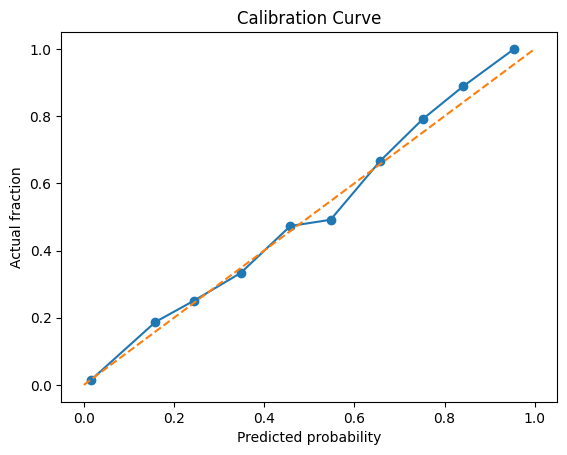

In [ ]:
import matplotlib.pyplot as plt

plt.plot(prob_pred, prob_true, marker="o")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("Predicted probability")
plt.ylabel("Actual fraction")
plt.title("Calibration Curve")
plt.show()

## Final Model

In [ ]:
final_model = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression())
])

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

In [ ]:
final_prob = final_model.predict_proba(X_test)[:, 1]

In [ ]:
final_pred = (final_prob >= 0.35).astype(int)

In [ ]:
final_pred = final_model.named_steps["model"].classes_[final_pred]

In [ ]:
print(final_pred[:10])
print(final_model.named_steps["model"].classes_)

['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']
['No' 'Yes']


In [ ]:
print(classification_report(y_test, final_pred))

              precision    recall  f1-score   support

          No       0.93      0.86      0.89      1035
         Yes       0.68      0.81      0.74       374

    accuracy                           0.85      1409
   macro avg       0.80      0.84      0.81      1409
weighted avg       0.86      0.85      0.85      1409



## Prediction Function

In [ ]:
def predict_churn(customer_data):
    customer_df = pd.DataFrame([customer_data])
    probability = final_model.predict_proba(customer_df)[:, 1][0]
    prediction = "Yes" if probability >= 0.35 else "No"
    return probability, prediction

In [ ]:
customer = {
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 50.0,
    "TotalCharges": 250.0,
    "numAdminTickets": 0,
    "numTechTickets": 1
}

In [ ]:
probability, prediction = predict_churn(customer)
print("Churn probability:", probability)
print("Prediction:", prediction)

Churn probability: 0.7807944333445368
Prediction: Yes


In [ ]:
sample = X_test.iloc[0].to_dict()

In [ ]:
probability, prediction = predict_churn(sample)
print("Churn probability:", probability)
print("Prediction:", prediction)

Churn probability: 0.0001437420215308147
Prediction: No


In [ ]:
direct_probability = final_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1][0]

print(direct_probability)

0.0001437420215308147


In [ ]:
import joblib

joblib.dump(final_model, "customer_churn_model.pkl")

['customer_churn_model.pkl']

In [ ]:
loaded_model = joblib.load("customer_churn_model.pkl")

In [ ]:
loaded_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1][0]

print(loaded_probability)

0.0001437420215308147
